# Importação de bibliotecas e inicialização

In [49]:
from google.cloud.dataproc_spark_connect import DataprocSparkSession
from google.cloud.dataproc_v1 import Session
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_selection import VarianceThreshold
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import geopandas as gpd
!pip install geobr -q
import geobr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 13.7 MB/s eta 0:00:00


In [1]:
# This will create a default Spark session
spark = DataprocSparkSession.builder.getOrCreate()

/usr/local/lib/python3.13/dist-packages/google/cloud/dataproc_spark_connect/session.py:336: UserWarning: Python version mismatch detected: Client is using Python 3.13, but Dataproc runtime 3.0 uses Python 3.12. This mismatch may cause issues with Python UDF (User Defined Function) compatibility. Consider using Python 3.12 for optimal UDF execution.
  dataproc_config: Session = self._get_dataproc_config()


█████████████████████████                                                       

# Recuperação dos Dados e Resumo Estatístico

In [4]:
from google.cloud import bigquery

# Inicializa o cliente do BigQuery padrão
client = bigquery.Client()

query = """
    SELECT *
    FROM `project-f1079166-4703-4cc3-975.refined_data_ml.refined_ml_features`
    WHERE ano BETWEEN 2019 AND 2024
"""

# Traz para um DataFrame do Pandas para inspecionar de forma rápida
df = client.query(query).to_dataframe()
display(df.head())

,cod_ibge,ano,pct_pedestre,pct_passageiro,pct_condutor,pct_pessoa_outros,pct_sexo_masculino,pct_sexo_feminino,pct_sexo_nao_disponivel,pct_idade_0a14,...,ipdm_riqueza,ipdm_escolaridade,ipdm_longevidade,ipdm_geral,mx_0a14,mx_15a29,mx_30a44,mx_45a59,mx_60_plus,mx_total
0,3532868,2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,363,891,702,652,0.0,0.0,0.0,46.0,314.0,64.0
1,3503158,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,249,761,347,452,0.0,0.0,22.0,95.0,481.0,123.0
2,3555901,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,308,584,755,549,4.0,44.0,0.0,35.0,583.0,166.0
3,3503158,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,252,792,298,447,25.0,44.0,23.0,95.0,49.0,146.0
4,3532843,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,316,576,729,54,0.0,31.0,0.0,98.0,193.0,9.0


In [7]:
print("--- RESUMO ESTATÍSTICO DAS VARIÁVEIS NUMÉRICAS ---")

colunas_para_descartar = ["cod_ibge", "ano"]

colunas_modelo = [
    coluna for coluna in df.columns
    if coluna not in colunas_para_descartar
]

# Estatísticas descritivas básicas
display(df[colunas_modelo].describe().transpose())

--- RESUMO ESTATÍSTICO DAS VARIÁVEIS NUMÉRICAS ---


,count,mean,std,min,25%,50%,75%,max
pct_pedestre,3860.0,0.041467,0.05031,0.0,0.0,0.033333,0.057166,0.666667
pct_passageiro,3860.0,0.302897,0.113718,0.0,0.247486,0.307692,0.362083,1.0
pct_condutor,3860.0,0.533497,0.138078,0.0,0.459882,0.535714,0.611762,1.0
pct_pessoa_outros,3860.0,0.122138,0.125907,0.0,0.047619,0.093023,0.155172,1.0
pct_sexo_masculino,3860.0,0.721345,0.101871,0.0,0.666667,0.716418,0.772032,1.0
...,...,...,...,...,...,...,...,...
mx_15a29,3870.0,9.50155,9.039694,0.0,2.0,8.0,14.0,107.0
mx_30a44,3870.0,21.30646,14.742228,0.0,13.0,19.0,28.0,115.0
mx_45a59,3870.0,61.434625,30.597847,0.0,46.0,61.0,77.0,221.0
mx_60_plus,3870.0,327.204393,116.54667,3.0,299.0,345.0,391.0,858.0



## Insights extraídos
* Carros e motos têm uma representatividade elevada, com 48% e 29% na media
* Há uma concentração fortíssima de vítimas nas faixas de 15 a 29 anos (média de 32,3%) e 30 a 44 anos (média de 32,0%). Juntas, essas duas faixas representam quase 65% de todas as pessoas envolvidas nos sinistros.
* Os acidentes se concentram majoritariamente à tarde (média de 33%) e à noite (média de 33,7%). Somados, esses dois turnos respondem por cerca de dois terços de todas as ocorrências.
* As colisões e choques lideram o panorama geral das origens dos acidentes, mostrando que os acidentes urbanos e em cruzamentos/vias estruturais pesam muito na base.
* Taxa de Acidentes por 100k habitantes: A mediana é de 333 acidentes por 100 mil habitantes, mas o valor máximo dispara para absurdos 2.578 por 100k. Isso prova que o risco não é homogêneo.
* Índice de Fatalidade Proporcional: Varia de 0 até quase 346, evidenciando que há cidades onde o volume de acidentes até pode ser moderado, mas a letalidade é desproporcionalmente alta.
* As colunas do IPDM (riqueza, escolaridade, longevidade e geral) mostram distribuições bem comportadas, com medianas em torno de 500 a 700 pontos.


Obs: o modelo vai te permitir responder (com base em dados) se os municípios com menor IPDM (maior vulnerabilidade social) são justamente aqueles que sofrem com as maiores taxas de fatalidade ou se o problema do trânsito afeta cidades ricas e industriais de forma diferente (por exemplo, cidades ricas com alta taxa de acidentes por frota circulante vs. cidades vulneráveis com alta letalidade por falta de infraestrutura viária adequada).



# Tratamento de Nulos

In [8]:
# 1. Conta a quantidade de nulos por coluna
nulos_por_coluna = df.isnull().sum()

# 2. Filtra apenas as colunas que têm mais de 0 nulos para a listagem não ficar poluída
nulos_filtrados = nulos_por_coluna[nulos_por_coluna > 0]

if len(nulos_filtrados) > 0:
    print("--- Colunas com valores  nulos ---")
    display(nulos_filtrados)
else:
    print("--- PERFEITO! Nenhuma coluna possui valores nulos. O dataset está pronto para o K-Means! ---")

--- ATENÇÃO: Encontramos colunas com valores nulos ---


,0
pct_pedestre,10
pct_passageiro,10
pct_condutor,10
pct_pessoa_outros,10
pct_sexo_masculino,10
pct_sexo_feminino,10
pct_sexo_nao_disponivel,10
pct_idade_0a14,10
pct_idade_15a29,10
pct_idade_30a44,10


In [10]:
# Preenche todos os valores nulos do DataFrame com 0
df = df.fillna(0)
print("Total de nulos após o preenchimento:", df.isnull().sum().sum())

Total de nulos após o preenchimento: 0


# Normalização dos Dados

## Normalização dos Dados (StandardScaler / Z-score)

**O que faz:** Transforma todas as variáveis do modelo para que tenham uma média igual a 0 e um desvio padrão igual a 1.

**Por que é essencial:** O K-Means agrupa os municípios calculando distâncias euclidianas (como se estivesse medindo distâncias geográficas em um mapa). Se  não ocorrer a padronização, variáveis com números grandes (como a taxa de acidentes que chega a 2.500) teriam um peso infinitamente maior no cálculo do que variáveis que variam de 0 a 1 (como as proporções). A padronização coloca todas as features na mesma proporção, garantindo que o IPDM, as taxas e as proporções de veículos tenham o mesmo peso de importância para o algoritmo.

In [14]:
# 3. Inicializar o StandardScaler
scaler = StandardScaler()

# 4. Criar uma cópia do dataframe para receber os valores escalonados
df_scaled = df.copy()

# 5. Aplicar a normalização nas colunas de features
df_scaled[colunas_modelo] = scaler.fit_transform(df[colunas_modelo])

print("--- DADOS NORMALIZADOS ---")
display(df_scaled[colunas_modelo].head())

--- DADOS NORMALIZADOS ---


,pct_pedestre,pct_passageiro,pct_condutor,pct_pessoa_outros,pct_sexo_masculino,pct_sexo_feminino,pct_sexo_nao_disponivel,pct_idade_0a14,pct_idade_15a29,pct_idade_30a44,...,ipdm_riqueza,ipdm_escolaridade,ipdm_longevidade,ipdm_geral,mx_0a14,mx_15a29,mx_30a44,mx_45a59,mx_60_plus,mx_total
0,-0.822555,-2.636415,-3.786883,-0.967765,-6.654627,-2.610907,-0.341873,-0.762232,-2.850489,-3.0502,...,0.257961,1.202137,0.952242,0.952915,-1.027195,-1.051228,-1.445454,-0.504500,-0.113312,-0.541525
1,-0.822555,-2.636415,-3.786883,-0.967765,-6.654627,-2.610907,-0.341873,-0.762232,-2.850489,-3.0502,...,-0.702285,0.550979,-1.011642,-0.335314,-1.027195,-1.051228,0.047051,1.097127,1.319776,1.306012
2,-0.822555,-2.636415,-3.786883,-0.967765,-6.654627,-2.610907,-0.341873,-0.762232,-2.850489,-3.0502,...,-0.205315,-0.335598,1.245441,0.289477,-0.512417,3.816822,-1.445454,-0.864049,2.195075,2.652522
3,-0.822555,-2.636415,-3.786883,-0.967765,-6.654627,-2.610907,-0.341873,-0.762232,-2.850489,-3.0502,...,-0.677015,0.706255,-1.282713,-0.367520,2.190167,3.816822,0.114892,1.097127,-2.387373,2.026238
4,-0.822555,-2.636415,-3.786883,-0.967765,-6.654627,-2.610907,-0.341873,-0.762232,-2.850489,-3.0502,...,-0.137930,-0.375669,1.101607,-2.898890,-1.027195,2.378535,-1.445454,1.195185,-1.151657,-2.263805


# Escolha das features

## Análise de features sem variação

In [20]:
# Identifica colunas com variância quase zero (constantes)
selector = VarianceThreshold(threshold=0.01) # Remove colunas onde a variância é menor que 1%
selector.fit(df_scaled[colunas_modelo])

# Quais colunas foram aprovadas?
colunas_uteis = [col for col, keep in zip(colunas_modelo, selector.get_support()) if keep]

print(f"Colunas originais: {len(colunas_modelo)}")
print(f"Colunas após remover baixa variância: {len(colunas_uteis)}")

Colunas originais: 68
Colunas após remover baixa variância: 68


* Não foi identificada nenhuma variável com pouca variação.

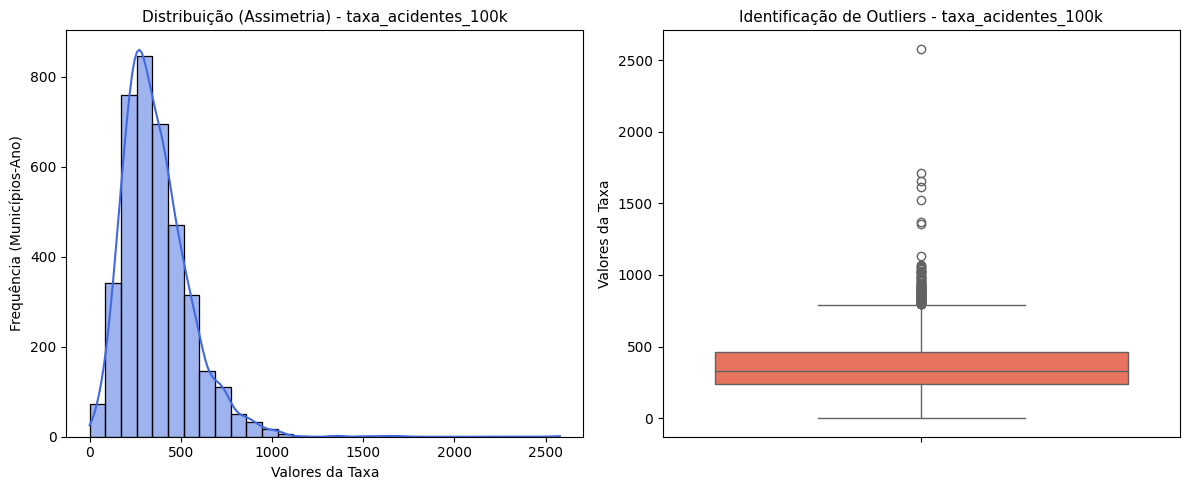

In [22]:
plt.figure(figsize=(12, 5))
variavel_alvo = "taxa_acidentes_100k"

# 1. Histograma + Curva de Densidade (Mostra a assimetria à direita)
plt.subplot(1, 2, 1)
sns.histplot(df[variavel_alvo], kde=True, color='royalblue', bins=30)
plt.title(f'Distribuição (Assimetria) - {variavel_alvo}', fontsize=11)
plt.xlabel('Valores da Taxa', fontsize=10)
plt.ylabel('Frequência (Municípios-Ano)', fontsize=10)

# 2. Boxplot (Mostra claramente a concentração e os outliers extremos)
plt.subplot(1, 2, 2)
sns.boxplot(y=df[variavel_alvo], color='tomato')
plt.title(f'Identificação de Outliers - {variavel_alvo}', fontsize=11)
plt.ylabel('Valores da Taxa', fontsize=10)

plt.tight_layout()
plt.show()

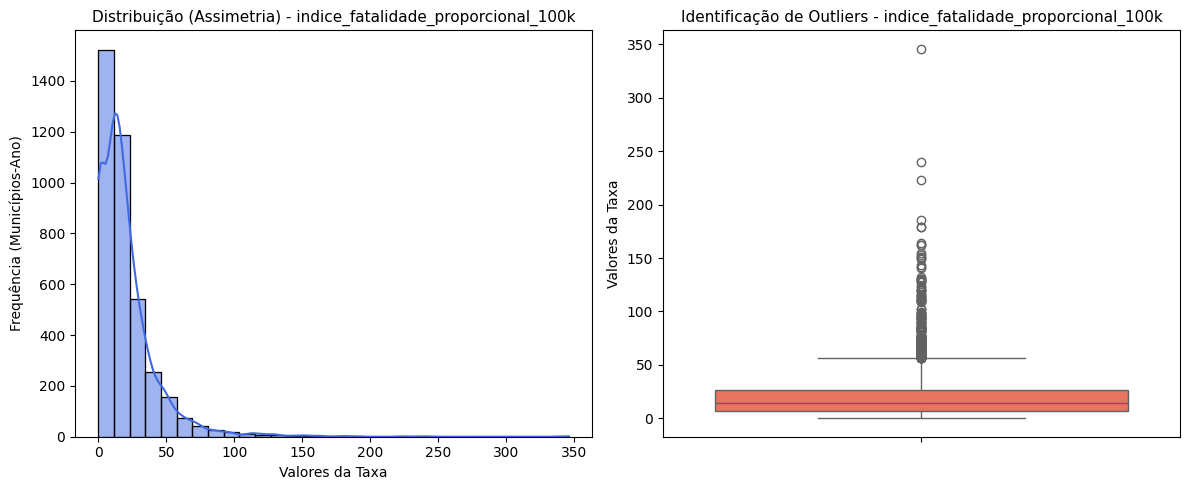

In [23]:
plt.figure(figsize=(12, 5))
variavel_alvo = "indice_fatalidade_proporcional_100k"

# 1. Histograma + Curva de Densidade (Mostra a assimetria à direita)
plt.subplot(1, 2, 1)
sns.histplot(df[variavel_alvo], kde=True, color='royalblue', bins=30)
plt.title(f'Distribuição (Assimetria) - {variavel_alvo}', fontsize=11)
plt.xlabel('Valores da Taxa', fontsize=10)
plt.ylabel('Frequência (Municípios-Ano)', fontsize=10)

# 2. Boxplot (Mostra claramente a concentração e os outliers extremos)
plt.subplot(1, 2, 2)
sns.boxplot(y=df[variavel_alvo], color='tomato')
plt.title(f'Identificação de Outliers - {variavel_alvo}', fontsize=11)
plt.ylabel('Valores da Taxa', fontsize=10)

plt.tight_layout()
plt.show()

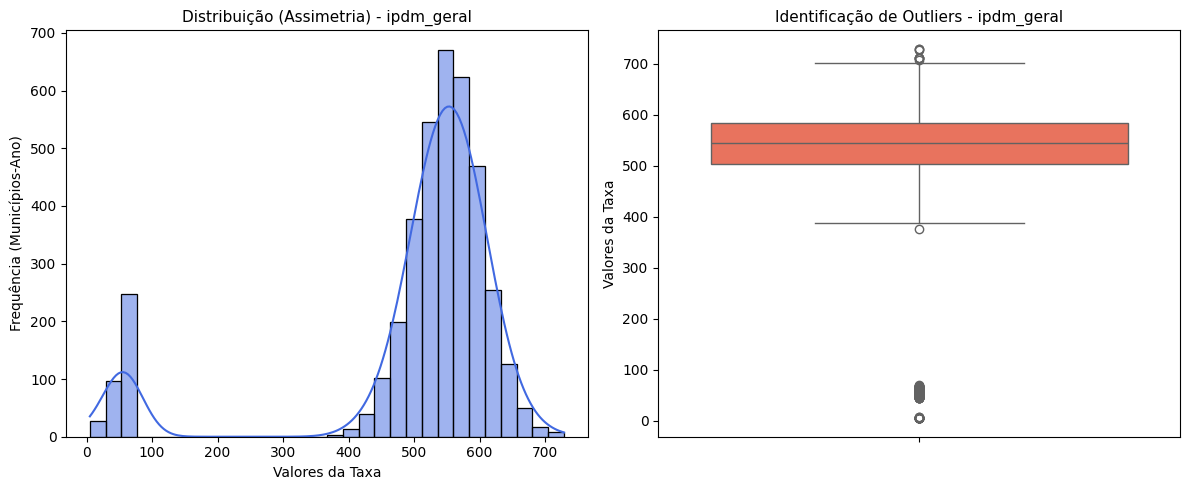

In [24]:
plt.figure(figsize=(12, 5))
variavel_alvo = "ipdm_geral"

# 1. Histograma + Curva de Densidade (Mostra a assimetria à direita)
plt.subplot(1, 2, 1)
sns.histplot(df[variavel_alvo], kde=True, color='royalblue', bins=30)
plt.title(f'Distribuição (Assimetria) - {variavel_alvo}', fontsize=11)
plt.xlabel('Valores da Taxa', fontsize=10)
plt.ylabel('Frequência (Municípios-Ano)', fontsize=10)

# 2. Boxplot (Mostra claramente a concentração e os outliers extremos)
plt.subplot(1, 2, 2)
sns.boxplot(y=df[variavel_alvo], color='tomato')
plt.title(f'Identificação de Outliers - {variavel_alvo}', fontsize=11)
plt.ylabel('Valores da Taxa', fontsize=10)

plt.tight_layout()
plt.show()

O fato de existir um segundo grupo menor deslocado para a esquerda (na faixa de 50 a 80) e os outliers inferiores escancara uma profunda assimetria e disparidade estrutural no Estado:

* O Estado de São Paulo é conhecido por ter polos industriais e agrícolas extremamente ricos, puxando a média para cima.
* Em contraponto, o estado também abriga municípios de pequeno porte com alta vulnerabilidade social, dependência crônica de repasses públicos e indicadores de longevidade ou escolaridade historicamente defasados, o que gera essa separação nítida em dois mundos no índice.

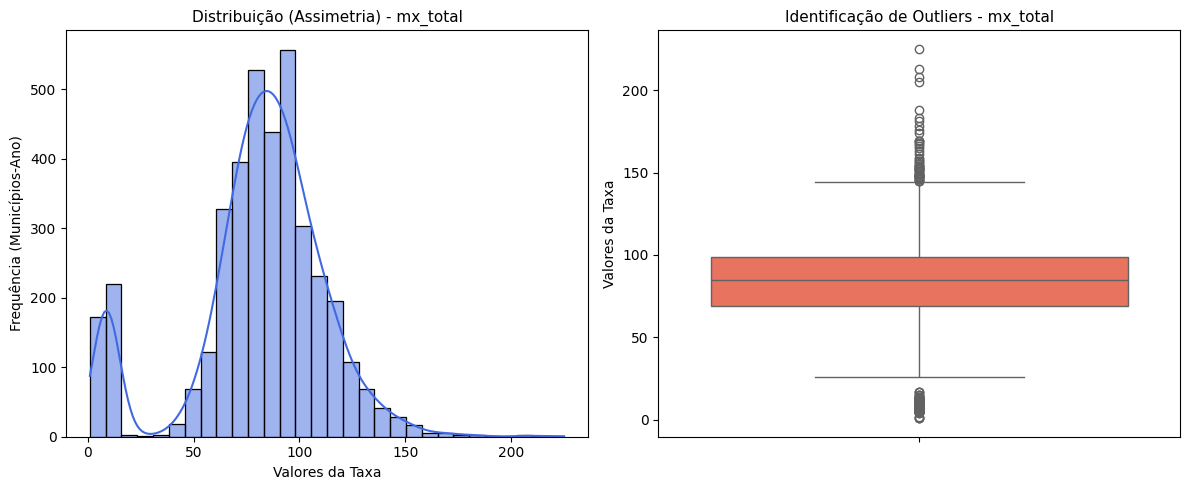

In [25]:
plt.figure(figsize=(12, 5))
variavel_alvo = "mx_total"

# 1. Histograma + Curva de Densidade (Mostra a assimetria à direita)
plt.subplot(1, 2, 1)
sns.histplot(df[variavel_alvo], kde=True, color='royalblue', bins=30)
plt.title(f'Distribuição (Assimetria) - {variavel_alvo}', fontsize=11)
plt.xlabel('Valores da Taxa', fontsize=10)
plt.ylabel('Frequência (Municípios-Ano)', fontsize=10)

# 2. Boxplot (Mostra claramente a concentração e os outliers extremos)
plt.subplot(1, 2, 2)
sns.boxplot(y=df[variavel_alvo], color='tomato')
plt.title(f'Identificação de Outliers - {variavel_alvo}', fontsize=11)
plt.ylabel('Valores da Taxa', fontsize=10)

plt.tight_layout()
plt.show()

## Análise de Correção

* Para investigar a intensidade e a direção das associações das variáveis, optou-se pela aplicação do coeficiente de correlação de Spearman em detrimento do coeficiente linear de Pearson.
* A escolha justifica-se pela natureza não-paramétrica dos dados analisados: as distribuições municipais de taxas de acidentes e fatalidade apresentam forte assimetria à direita e a presença expressiva de valores extremos (outliers), decorrentes da heterogeneidade entre pequenos municípios do interior e grandes polos urbanos ou rodoviários do Estado de São Paulo.
* Por operar sobre a ordenação (ranks) das observações em vez de seus valores absolutos, a métrica de Spearman mostra-se robusta a distorções causadas por outliers e capaz de capturar relações não-lineares, conferindo maior rigor estatístico à etapa exploratória.

In [26]:
variavel_central = "taxa_acidentes_100k"

# 2. Calcula a correlação de Spearman de TODAS as colunas numéricas em relação à variável central
corr_spearman = df[colunas_modelo].corr(method='spearman')[variavel_central].sort_values(ascending=False)

# 3. Exibe o ranking das variáveis que mais sobressaem (positiva e negativamente)
print(f"--- TOP 10 CORRELAÇÕES DE SPEARMAN COM: {variavel_central} ---")
display(corr_spearman.head(10))

print(f"\n--- TOP 10 CORRELAÇÕES NEGATIVAS COM: {variavel_central} ---")
display(corr_spearman.tail(10))

--- TOP 10 CORRELAÇÕES DE SPEARMAN COM: taxa_acidentes_100k ---


,taxa_acidentes_100k
taxa_acidentes_100k,1.000000
pct_veiculos_outros,0.394574
pct_engavetamento,0.355815
pct_nacionalidade_estrangeira,0.341684
ipdm_riqueza,0.291532
indice_fatalidade_proporcional_100k,0.278641
pct_sexo_nao_disponivel,0.257072
pct_pessoa_outros,0.255736
pct_nacionalidade_nao_disponivel,0.251340
pct_atrop_animal,0.225774



--- TOP 10 CORRELAÇÕES NEGATIVAS COM: taxa_acidentes_100k ---


,taxa_acidentes_100k
pct_acidentes_leves,-0.094384
pct_acidentes_graves,-0.097788
pct_capotamento,-0.101245
pct_condutor,-0.113936
pct_frota_20_plus,-0.159237
pct_acidentes_noite,-0.162485
pct_envolvem_carro,-0.165663
pct_sexo_masculino,-0.228917
pct_nacionalidade_brasileira,-0.237035
pct_veiculos_carro,-0.308952


In [32]:
matriz_spearman = df[colunas_modelo].corr(method='spearman')
display(matriz_spearman)

,pct_pedestre,pct_passageiro,pct_condutor,pct_pessoa_outros,pct_sexo_masculino,pct_sexo_feminino,pct_sexo_nao_disponivel,pct_idade_0a14,pct_idade_15a29,pct_idade_30a44,...,ipdm_riqueza,ipdm_escolaridade,ipdm_longevidade,ipdm_geral,mx_0a14,mx_15a29,mx_30a44,mx_45a59,mx_60_plus,mx_total
pct_pedestre,1.000000,-0.063623,-0.236429,0.048548,-0.023156,0.040234,0.106457,0.210978,0.082063,-0.011774,...,0.102804,-0.083540,-0.076915,-0.060345,0.124241,0.083383,0.031020,0.068935,-0.006501,-0.089446
pct_passageiro,-0.063623,1.000000,-0.454894,-0.223683,-0.125521,0.198493,-0.121714,0.103348,0.103630,-0.020434,...,0.030722,-0.023788,0.003920,0.010925,-0.002494,0.000866,-0.000713,0.019331,0.010498,0.013318
pct_condutor,-0.236429,-0.454894,1.000000,-0.536066,0.218874,-0.130147,-0.292100,-0.217600,-0.018603,0.072789,...,-0.019909,0.074381,0.017353,0.033503,-0.029491,-0.055567,-0.001367,-0.029900,0.028948,0.039407
pct_pessoa_outros,0.048548,-0.223683,-0.536066,1.000000,-0.138044,0.050209,0.413148,0.121580,0.010768,-0.021359,...,0.083358,-0.040075,0.033140,0.034369,0.037743,0.063419,-0.006234,0.020399,-0.022874,-0.030776
pct_sexo_masculino,-0.023156,-0.125521,0.218874,-0.138044,1.000000,-0.942878,-0.118527,-0.187595,-0.030307,0.131663,...,-0.072903,-0.036089,-0.115207,-0.085636,-0.003647,0.022994,0.022468,-0.006180,-0.012906,-0.079089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
mx_15a29,0.083383,0.000866,-0.055567,0.063419,0.022994,-0.031340,0.082933,0.073596,0.048102,-0.022332,...,0.019747,-0.112944,-0.069131,-0.075362,0.084681,1.000000,0.088141,0.090167,0.059518,0.075342
mx_30a44,0.031020,-0.000713,-0.001367,-0.006234,0.022468,-0.035423,0.062133,0.018732,0.003637,0.013672,...,-0.040058,-0.113714,-0.060847,-0.073590,-0.009250,0.088141,1.000000,0.202324,0.143821,0.207053
mx_45a59,0.068935,0.019331,-0.029900,0.020399,-0.006180,-0.013712,0.078217,0.047057,0.008899,-0.022134,...,-0.069158,-0.055725,-0.050705,-0.085127,0.032542,0.090167,0.202324,1.000000,0.239490,0.304259
mx_60_plus,-0.006501,0.010498,0.028948,-0.022874,-0.012906,0.009221,0.034110,0.013258,0.014788,-0.003711,...,-0.049453,-0.029588,0.012089,-0.053350,0.010969,0.059518,0.143821,0.239490,1.000000,0.483776


In [33]:
variavel_alvo = "taxa_acidentes_100k"  # Pode trocar por "ipdm_geral" se quiser analisar o desenvolvimento

# 2. Extrai a correlação dela com todas as outras e remove ela mesma
corrs_alvo = matriz_spearman[variavel_alvo].drop(variavel_alvo)

# 3. Exibe o Top 10 maiores correlações positivas e negativas
print(f"--- TOP 10 FATORES COM MAIOR ASSOCIAÇÃO POSITIVA COM: {variavel_alvo} ---")
display(corrs_alvo.nlargest(10))

print(f"\n--- TOP 10 FATORES COM MAIOR ASSOCIAÇÃO NEGATIVA (INVERSA) COM: {variavel_alvo} ---")
display(corrs_alvo.nsmallest(10))

--- TOP 10 FATORES COM MAIOR ASSOCIAÇÃO POSITIVA COM: taxa_acidentes_100k ---


,taxa_acidentes_100k
pct_veiculos_outros,0.394574
pct_engavetamento,0.355815
pct_nacionalidade_estrangeira,0.341684
ipdm_riqueza,0.291532
indice_fatalidade_proporcional_100k,0.278641
pct_sexo_nao_disponivel,0.257072
pct_pessoa_outros,0.255736
pct_nacionalidade_nao_disponivel,0.251340
pct_atrop_animal,0.225774
pct_acidentes_manha,0.224772



--- TOP 10 FATORES COM MAIOR ASSOCIAÇÃO NEGATIVA (INVERSA) COM: taxa_acidentes_100k ---


,taxa_acidentes_100k
pct_veiculos_carro,-0.308952
pct_nacionalidade_brasileira,-0.237035
pct_sexo_masculino,-0.228917
pct_envolvem_carro,-0.165663
pct_acidentes_noite,-0.162485
pct_frota_20_plus,-0.159237
pct_condutor,-0.113936
pct_capotamento,-0.101245
pct_acidentes_graves,-0.097788
pct_acidentes_leves,-0.094384


In [35]:
# Cria uma cópia da matriz e zera a diagonal principal para não pegar a correlação da variável com ela mesma
matriz_limpa = matriz_spearman.copy()
np.fill_diagonal(matriz_limpa.values, 0)

# Encontra pares com correlação de Spearman absoluta superior a 0.85
limiar = 0.85
pares_redundantes = []

colunas = matriz_limpa.columns
for i in range(len(colunas)):
    for j in range(i+1, len(colunas)):
        val = matriz_limpa.iloc[i, j]
        if abs(val) > limiar:
            pares_redundantes.append((colunas[i], colunas[j], val))

# Exibe os pares redundantes encontrados
print(f"--- PARES COM ALTA REDUNDÂNCIA (Spearman > {limiar}) ---")
if len(pares_redundantes) > 0:
    for var1, var2, corr in sorted(pares_redundantes, key=lambda x: abs(x[2]), reverse=True):
        print(f"• {var1}  <--->  {var2}  (Correlação: {corr:.2f})")
else:
    print("Nenhuma redundância crítica encontrada com esse limiar.")

--- PARES COM ALTA REDUNDÂNCIA (Spearman > 0.85) ---
• pct_acidente_primario_atropelamento  <--->  pct_atropelamento_pedestre  (Correlação: 1.00)
• pct_veiculos_onibus  <--->  pct_envolvem_onibus  (Correlação: 0.99)
• pct_veiculos_bicicleta  <--->  pct_envolvem_bicicleta  (Correlação: 0.99)
• pct_nacionalidade_brasileira  <--->  pct_nacionalidade_nao_disponivel  (Correlação: -0.98)
• pct_veiculos_caminhao  <--->  pct_envolvem_caminhao  (Correlação: 0.98)
• pct_acidente_primario_choque  <--->  pct_choque  (Correlação: 0.97)
• pct_sexo_masculino  <--->  pct_sexo_feminino  (Correlação: -0.94)
• pct_acidentes_fatais  <--->  indice_fatalidade_proporcional_100k  (Correlação: 0.92)


In [37]:
colunas_para_remover = [
    'pct_atropelamento_pedestre',
    'pct_envolvem_onibus',
    'pct_envolvem_bicicleta',
    'pct_nacionalidade_nao_disponivel',
    'pct_envolvem_caminhao',
    'pct_choque',
    'pct_sexo_masculino',
    'indice_fatalidade_proporcional_100k'
]

# Atualiza a sua lista de colunas do modelo tirando as redundantes
colunas_modelo_limpas = [col for col in colunas_modelo if col not in colunas_para_remover]

print(f"Colunas originais: {len(colunas_modelo)}")
print(f"Colunas após limpeza de redundância: {len(colunas_modelo_limpas)}")

Colunas originais: 68
Colunas após limpeza de redundância: 60


In [41]:
matriz_spearman = df[colunas_modelo_limpas].corr(method='spearman')
display(matriz_spearman)

,pct_pedestre,pct_passageiro,pct_condutor,pct_pessoa_outros,pct_sexo_feminino,pct_sexo_nao_disponivel,pct_idade_0a14,pct_idade_15a29,pct_idade_30a44,pct_idade_45a59,...,ipdm_riqueza,ipdm_escolaridade,ipdm_longevidade,ipdm_geral,mx_0a14,mx_15a29,mx_30a44,mx_45a59,mx_60_plus,mx_total
pct_pedestre,1.000000,-0.063623,-0.236429,0.048548,0.040234,0.106457,0.210978,0.082063,-0.011774,-0.027466,...,0.102804,-0.083540,-0.076915,-0.060345,0.124241,0.083383,0.031020,0.068935,-0.006501,-0.089446
pct_passageiro,-0.063623,1.000000,-0.454894,-0.223683,0.198493,-0.121714,0.103348,0.103630,-0.020434,-0.000402,...,0.030722,-0.023788,0.003920,0.010925,-0.002494,0.000866,-0.000713,0.019331,0.010498,0.013318
pct_condutor,-0.236429,-0.454894,1.000000,-0.536066,-0.130147,-0.292100,-0.217600,-0.018603,0.072789,0.068484,...,-0.019909,0.074381,0.017353,0.033503,-0.029491,-0.055567,-0.001367,-0.029900,0.028948,0.039407
pct_pessoa_outros,0.048548,-0.223683,-0.536066,1.000000,0.050209,0.413148,0.121580,0.010768,-0.021359,-0.014256,...,0.083358,-0.040075,0.033140,0.034369,0.037743,0.063419,-0.006234,0.020399,-0.022874,-0.030776
pct_sexo_feminino,0.040234,0.198493,-0.130147,0.050209,1.000000,-0.068487,0.180881,0.077275,-0.096944,0.015048,...,0.101095,0.035351,0.113916,0.094067,0.011677,-0.031340,-0.035423,-0.013712,0.009221,0.070155
pct_sexo_nao_disponivel,0.106457,-0.121714,-0.292100,0.413148,-0.068487,1.000000,0.093258,0.024567,-0.024723,-0.069090,...,0.089672,0.013234,0.058965,0.085096,0.051024,0.082933,0.062133,0.078217,0.034110,-0.045256
pct_idade_0a14,0.210978,0.103348,-0.217600,0.121580,0.180881,0.093258,1.000000,-0.090211,-0.049398,-0.058590,...,0.034109,-0.019228,-0.036633,-0.013767,0.095622,0.073596,0.018732,0.047057,0.013258,-0.005334
pct_idade_15a29,0.082063,0.103630,-0.018603,0.010768,0.077275,0.024567,-0.090211,1.000000,-0.324428,-0.358397,...,0.090298,-0.016501,0.030031,0.047593,0.055243,0.048102,0.003637,0.008899,0.014788,-0.073742
pct_idade_30a44,-0.011774,-0.020434,0.072789,-0.021359,-0.096944,-0.024723,-0.049398,-0.324428,1.000000,-0.227928,...,0.100371,0.046916,0.001216,0.046839,-0.010539,-0.022332,0.013672,-0.022134,-0.003711,-0.096392
pct_idade_45a59,-0.027466,-0.000402,0.068484,-0.014256,0.015048,-0.069090,-0.058590,-0.358397,-0.227928,1.000000,...,0.005583,-0.036729,-0.036424,-0.010670,-0.003036,-0.006720,-0.003709,0.026764,-0.007789,0.046629


In [42]:
colunas_modelo = colunas_modelo_limpas

# Critério do cotovelo (Elbow Method)

Para a determinação do número ideal de agrupamentos ($K$), utilizou-se o critério do cotovelo (Elbow Method) baseado na métrica de Inércia (Soma dos Erros Quadráticos - SSE). O algoritmo foi iterado para valores de $K$ variando de 1 a 10, avaliando-se a taxa de decaimento da variância intra-cluster até a identificação do ponto de inflexão da curva.

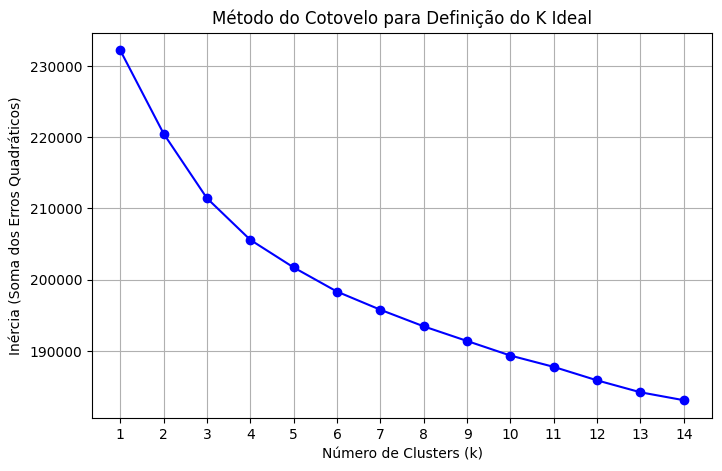

In [43]:
inercia = []
k_valores = range(1, 15)

for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled[colunas_modelo])
    inercia.append(kmeans.inertia_)

# Plotando o gráfico do Cotovelo
plt.figure(figsize=(8, 5))
plt.plot(k_valores, inercia, marker='o', linestyle='-', color='b')
plt.title('Método do Cotovelo para Definição do K Ideal', fontsize=12)
plt.xlabel('Número de Clusters (k)', fontsize=10)
plt.ylabel('Inércia (Soma dos Erros Quadráticos)', fontsize=10)
plt.xticks(k_valores)
plt.grid(True)
plt.show()

## Análise do Gráfico

* **Comportamento da Curva:** A inércia (Soma dos Erros Quadráticos) decresce continuamente conforme aumentamos o número de clusters ($k$), o que é o comportamento esperado, já que quanto mais grupos criamos, mais próximos os pontos ficam de seus centroides.
* **Ponto de Inflexão:** A curva não faz um "ângulo reto" perfeito, mas apresenta uma suave inflexão (mudança de ritmo na queda) na região entre $k = 4$ e $k = 5$. A partir de $k = 5$, a linha se torna quase linear e a redução da inércia por cluster adicional passa a ser muito pequena.
* **Tomada de decisão:** Adotar $k = 5$ equilibra perfeitamente a compactação matemática dos dados com a interpretabilidade de negócio. Isso permite criar tipologias claras.


# Modelagem dos Clusters

In [45]:
# 1. Definir o k escolhido
k_escolhido = 5
kmeans_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)

# 2. Treinar o modelo com as features normalizadas e salvar o cluster no df original
df['cluster'] = kmeans_final.fit_predict(df_scaled[colunas_modelo])

# 3. Verificar quantos registros/municípios-ano caíram em cada cluster
print("--- CONTAGEM DE REGISTROS POR CLUSTER ---")
contagem_clusters = df['cluster'].value_counts().sort_index()
display(contagem_clusters)

# 4. O Coração da Análise: Extrair a média das principais métricas por cluster
colunas_perfil = [
    "taxa_acidentes_100k",
    "indice_fatalidade_proporcional_100k",
    "ipdm_geral",
    "pct_envolvem_motocicleta",
    "pct_acidente_primario_colisao"
]

perfil_clusters = df.groupby('cluster')[colunas_perfil].mean().reset_index()

print("\n--- PERFIL MÉDIO DOS CLUSTERS (Para fundamentar a política pública) ---")
display(perfil_clusters)

--- CONTAGEM DE REGISTROS POR CLUSTER ---


,count
cluster,
0,669
1,1121
2,1021
3,163
4,896



--- PERFIL MÉDIO DOS CLUSTERS (Para fundamentar a política pública) ---


,cluster,taxa_acidentes_100k,indice_fatalidade_proporcional_100k,ipdm_geral,pct_envolvem_motocicleta,pct_acidente_primario_colisao
0,0,270.259120,24.094167,494.405082,0.189781,0.294695
1,1,367.673172,16.309390,507.863515,0.479146,0.502228
2,2,435.302925,16.353267,511.326151,0.364174,0.327903
3,3,498.229376,31.548474,473.742331,0.183940,0.223081
4,4,330.408864,23.353709,503.737723,0.308990,0.286224


### Definindo o que os clusters representam

In [ ]:
# 1. Calcula a média de todas as variáveis limpas para cada cluster
perfil_clusters_medio = df.groupby('cluster')[colunas_modelo_limpas].mean()

# 2. Calcula a média geral de todo o Estado de São Paulo
media_geral_estado = df[colunas_modelo_limpas].mean()

# 3. Calcula o desvio percentual de cada cluster em relação à média do estado
# (Valores positivos = acima da média estadual | Valores negativos = abaixo da média estadual)
perfil_relativo = ((perfil_clusters_medio - media_geral_estado) / media_geral_estado) * 100

print("--- PERFIL RELATIVO DOS CLUSTERS (% de desvio em relação à média de SP) ---")
display(perfil_relativo.T)

## Visualização dos Clusters

In [66]:

# Recupera arquivo da malha de SP
nome_do_arquivo = 'malha_sp.json'
malha_sp = gpd.read_file(nome_do_arquivo)

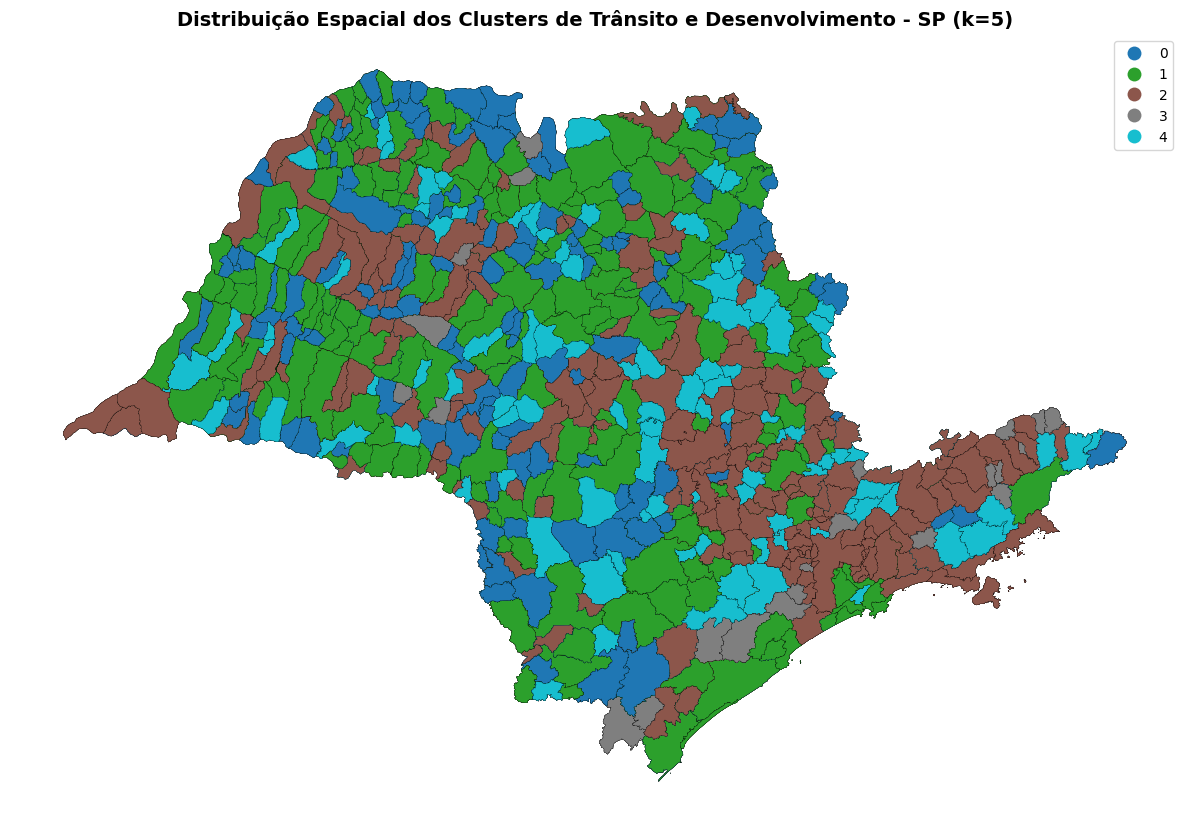

In [64]:
if 'id' in malha_sp.columns:
    malha_sp['cod_ibge_geo'] = malha_sp['id'].astype(int)
else:
    malha_sp['cod_ibge_geo'] = malha_sp['id_municipio'].astype(int)

df['cod_ibge_int'] = df['cod_ibge'].astype(int)
df_mapa = malha_sp.merge(df, left_on='cod_ibge_geo', right_on='cod_ibge_int')

# Garante que o cluster é tratado como categoria (string ou int categórico) para coloração distinta
df_mapa['cluster_cat'] = df_mapa['cluster'].astype(str)

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

df_mapa.plot(
    column='cluster_cat',
    ax=ax,
    legend=True,
    cmap='tab10',           # Paleta com cores altamente contrastantes
    edgecolor='black',
    linewidth=0.15
)

plt.title('Distribuição Espacial dos Clusters de Trânsito e Desenvolvimento - SP (k=5)', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

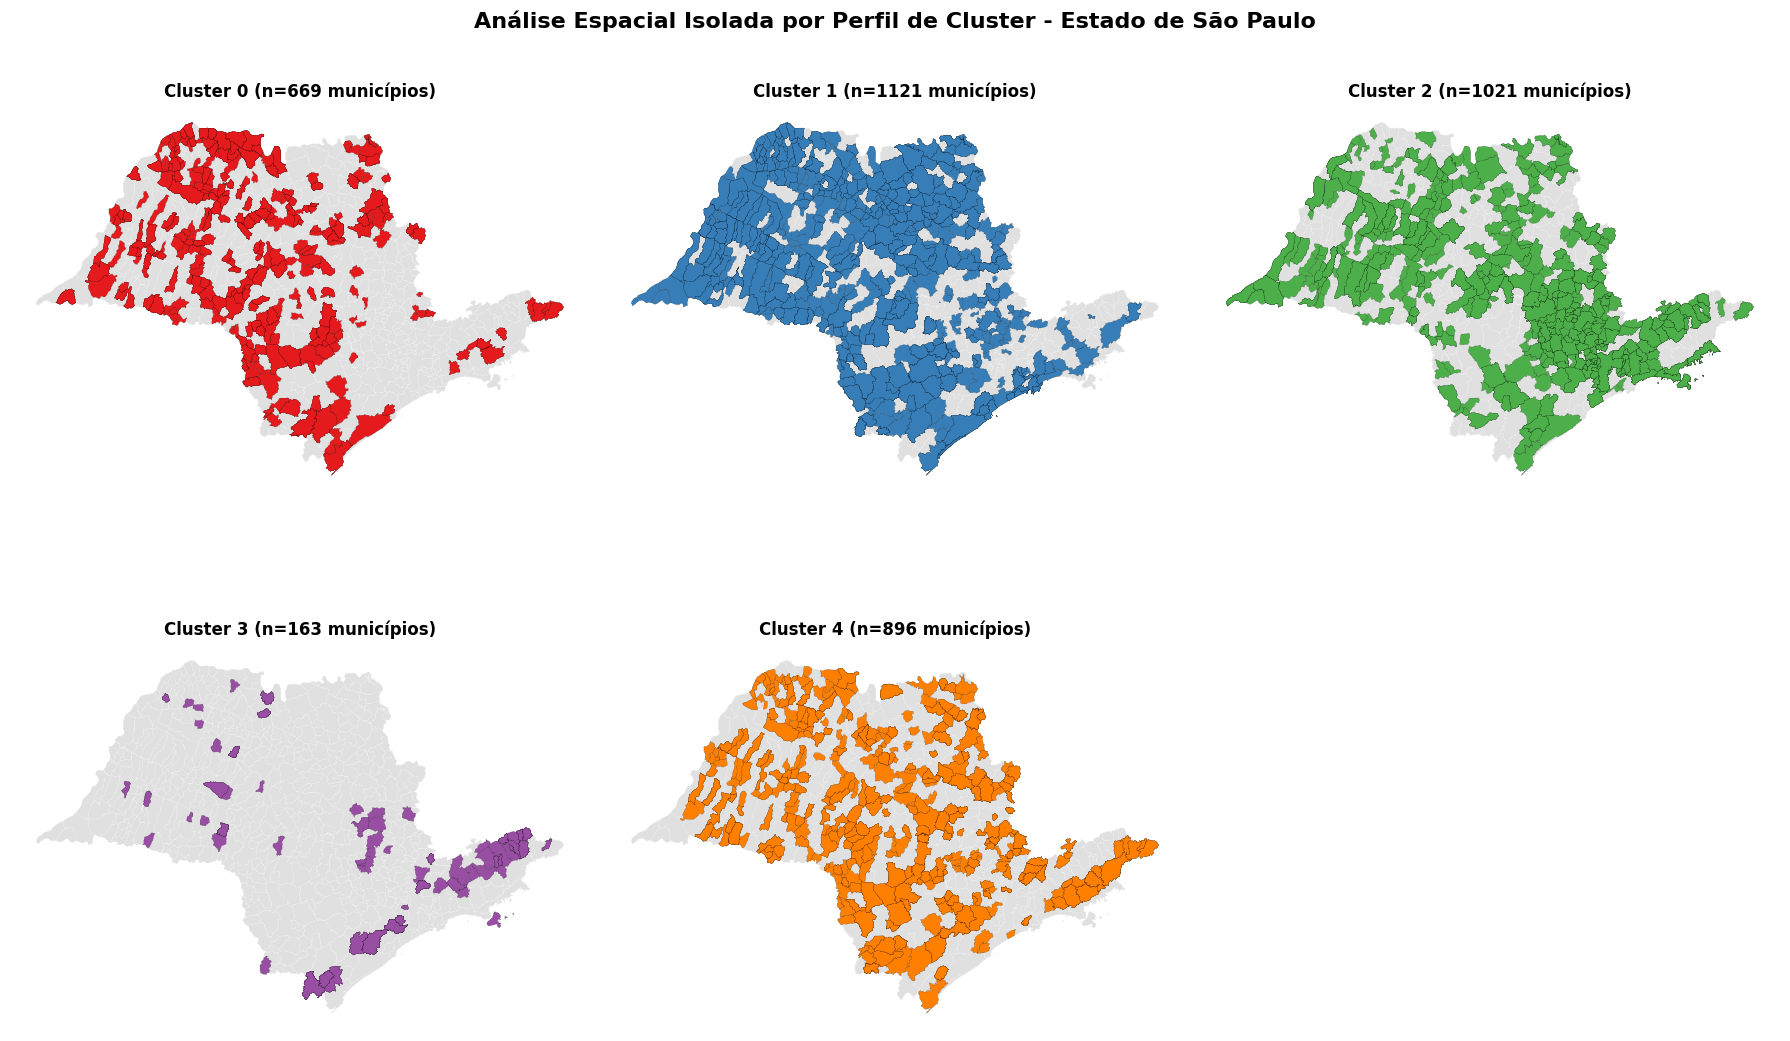

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Lista de cores fortes para destacar cada cluster individualmente
cores_clusters = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

clusters_unicos = sorted(df_mapa['cluster'].unique())

for i, cl in enumerate(clusters_unicos):
    ax = axes[i]

    # Plota primeiro o fundo do estado em cinza claro para dar contexto geográfico
    df_mapa.plot(ax=ax, color='#e0e0e0', edgecolor='white', linewidth=0.1)

    # Plota por cima apenas os municípios pertencentes ao cluster atual com cor de destaque
    subset = df_mapa[df_mapa['cluster'] == cl]
    subset.plot(ax=ax, color=cores_clusters[i % len(cores_clusters)], edgecolor='black', linewidth=0.1)

    ax.set_title(f'Cluster {cl} (n={len(subset)} municípios)', fontsize=12, fontweight='bold')
    ax.axis('off')

# Remove o último subplot vazio (já que temos 5 clusters e 6 espaços na grade)
fig.delaxes(axes[5])

plt.suptitle('Análise Espacial Isolada por Perfil de Cluster - Estado de São Paulo', fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout()
plt.show()